# Phase B: Erste Baseline mit scikit-learn

Schritte 6 bis 8 aus `LERNPLAN.md`, für alle sechs Befundarten.

## Setup

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().resolve()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
METER_DIR = ROOT / "data" / "processed" / "real_meters"
BILDER = ROOT / "docs" / "assets" / "lernpfad"

sys.path.insert(0, str(ROOT))

## Schritt 6: Kennzahlen pro Station

Für jede Station brauchen wir eine Zeile mit Zahlen. Bevor wir rechnen, schreiben wir für jede Befundart auf, woran man sie erkennen könnte und in welche Richtung die Kennzahl gehen sollte. Erst danach schauen wir, ob es stimmt.

| Befund | Idee | Kennzahl | Erwartung bei Befund |
|---|---|---|---|
| ventil | Ventil schließt nicht, Wasser läuft nachts im Sommer durch | `nachtfluss`: Median Durchfluss Sommer 2024, 0 bis 5 Uhr | höher |
| daemmung | Wasser verliert im Keller zusätzlich Wärme, Rücklauf wird kälter | `winter_ruecklauf`: Median Rücklauf Winter 2023/24 | niedriger |
| filter | Verstopfter Filter bremst das Wasser, es fließt langsamer und kühlt stärker ab | `winter_spreizung`: Median Spreizung im Winter, nur Stunden mit Durchfluss | höher |
| durchfluss | Durchfluss zu hoch eingestellt, bei viel Bedarf fließt mehr als nötig | `fluss_pro_kw`: 99-%-Wert Durchfluss im Winter / Anschlusswert | höher |
| temperatur | Rücklauf tagsüber zu hoch, deshalb wurde der Sollwert gesenkt | `ruecklauf_tag`: Median Rücklauf im Winter, 8 bis 20 Uhr | höher |
| ueberdimensioniert | Vertrag größer als nötig, die Leistung wird nie ausgeschöpft | `auslastung`: 99-%-Wert Leistung im Winter / alter Vertrag | niedriger |

Der 99-%-Wert ist fast das Maximum, aber einzelne Ausreißer verschieben ihn nicht. Die Spreizung nur in Stunden mit Durchfluss, weil sie sonst nichts bedeutet (Phase A, unmögliche Werte).

In [2]:
labels = pd.read_csv(ROOT / "data" / "processed" / "modell_labels.csv")

Für `fluss_pro_kw` brauchen wir noch den Anschlusswert jeder Station. Der steht in `hast_features.csv` aus Notebook 00:

In [3]:
anschluss = pd.read_csv(ROOT / "data" / "processed" / "hast_features.csv")
anschluss = anschluss[["Zählernummer", "anschlusswert_kw"]].rename(columns={"Zählernummer": "zaehler"})

In [4]:
zeilen = []
for z in labels["zaehler"]:
    d = pd.read_csv(METER_DIR / f"{z}.csv", parse_dates = ["Timestamp"])
    
    sommer = d[(d["Timestamp"] >= "2024-06-01") & (d["Timestamp"] < "2024-09-01")]
    nacht = sommer[sommer["Timestamp"].dt.hour < 5]
    
    winter = d[(d["Timestamp"] >= "2023-10-01") & (d["Timestamp"] < "2024-04-01")]
    mit_fluss = winter[winter["Volume flow (l/h)"] > 0]
    tagsueber = winter[(winter["Timestamp"].dt.hour >= 8) & (winter["Timestamp"].dt.hour < 20)]
    
    zeilen.append({
        "zaehler": z,
        "nachtfluss": nacht["Volume flow (l/h)"].median(),
        "winter_ruecklauf": winter["Return temperature (°C)"].median(),
        "winter_spreizung": mit_fluss["Temperature difference (°C)"].median(),
        "fluss_p99": winter["Volume flow (l/h)"].quantile(0.99),
        "ruecklauf_tag": tagsueber["Return temperature (°C)"].median(),
        "leistung_p99": winter["Power (kW)"].quantile(0.99),
    })

In [5]:
kennzahlen = pd.DataFrame(zeilen)
tabelle = kennzahlen.merge(labels, on="zaehler")
tabelle = tabelle.merge(anschluss, on="zaehler", how="left")

Die beiden Verhältnisse rechnen wir erst jetzt aus, weil Anschlusswert und Vertrag in der Tabelle stehen:

In [6]:
tabelle["fluss_pro_kw"] = tabelle["fluss_p99"] / tabelle["anschlusswert_kw"]
tabelle["auslastung"] = tabelle["leistung_p99"] / tabelle["vertrag_alt_kw"]

In [7]:
tabelle[["zaehler", "nachtfluss", "winter_ruecklauf", "winter_spreizung", "fluss_pro_kw", "ruecklauf_tag", "auslastung"]].describe()

,zaehler,nachtfluss,winter_ruecklauf,winter_spreizung,fluss_pro_kw,ruecklauf_tag,auslastung
count,5.600000e+01,53.000000,54.000000,54.000000,53.000000,54.000000,35.000000
mean,7.514527e+07,59.584906,45.827778,24.343519,39.882113,47.043519,0.963171
std,5.741704e+06,161.718825,12.237110,10.245192,17.689707,12.219556,0.289540
min,6.527385e+07,0.000000,25.400000,0.100000,7.005000,25.500000,0.475710
25%,6.895637e+07,0.000000,37.075000,19.175000,30.375000,38.600000,0.770172
50%,7.216778e+07,0.000000,45.900000,27.300000,33.211000,47.650000,0.950717
75%,8.091217e+07,16.000000,53.750000,30.750000,47.125000,54.650000,1.076316
max,8.101943e+07,753.000000,75.100000,40.600000,105.250000,74.800000,1.838194


Bei 2 bis 3 Stationen fehlen Sommer- oder Winterdaten. Die `auslastung` gibt es nur für 35 Stationen, weil nur dort der alte Vertrag im Protokoll steht.

Jetzt die erste Vermutung prüfen, die Dämmung:

In [8]:
tabelle.groupby("daemmung")["winter_ruecklauf"].median()

daemmung
False    47.6
True     38.6
Name: winter_ruecklauf, dtype: float64

Mit Dämmungsbefund ist der Rücklauf 9 Grad kälter, wie erwartet. Und beim Ventil, wo heißes Wasser ungenutzt durchläuft?

In [9]:
tabelle.groupby("ventil")["winter_ruecklauf"].median()

ventil
False    41.55
True     55.10
Name: winter_ruecklauf, dtype: float64

Beim Ventil ist es genau umgekehrt, wärmer. Dieselbe Kennzahl zeigt bei zwei Befunden in entgegengesetzte Richtungen. Und 6 der 11 Ventilstationen haben auch einen Dämmungsbefund, da können sich die beiden Effekte aufheben. Jeder Befund braucht also seine eigene Kennzahl.

Jetzt alle Befunde mit ihrer Kennzahl aus der Tabelle oben:

In [10]:
plan = {
    "ventil": "nachtfluss",
    "daemmung": "winter_ruecklauf",
    "filter": "winter_spreizung",
    "durchfluss": "fluss_pro_kw",
    "temperatur": "ruecklauf_tag",
    "ueberdimensioniert": "auslastung",
}

for b, k in plan.items():
    mit = tabelle[tabelle[b] == 1][k].median()
    ohne = tabelle[tabelle[b] == 0][k].median()
    print(f"{b:20s} {k:18s} mit Befund: {mit:7.2f}   ohne Befund: {ohne:7.2f}")

ventil               nachtfluss         mit Befund:   67.00   ohne Befund:    0.00
daemmung             winter_ruecklauf   mit Befund:   38.60   ohne Befund:   47.60
filter               winter_spreizung   mit Befund:   25.00   ohne Befund:   28.60
durchfluss           fluss_pro_kw       mit Befund:   31.64   ohne Befund:   35.83
temperatur           ruecklauf_tag      mit Befund:   49.60   ohne Befund:   43.40
ueberdimensioniert   auslastung         mit Befund:    0.67   ohne Befund:    0.97


- **Ventil:** nachts 67 l/h mit Befund, 0 ohne. Stimmt.
- **Dämmung:** Rücklauf 38,6 gegen 47,6 °C, kälter. Stimmt.
- **Filter:** Spreizung 25,0 gegen 28,6 Grad, also kleiner und nicht größer. Die Vermutung stimmt nicht.
- **Durchfluss:** 31,6 gegen 35,8 l/h pro kW, eher weniger. Auch nicht wie vermutet.
- **Temperatur:** Rücklauf tagsüber 49,6 gegen 43,4 °C, höher. Stimmt.
- **Überdimensioniert:** Auslastung 0,67 gegen 0,97. Die Stationen mit verkleinertem Vertrag haben vorher nur zwei Drittel davon gebraucht. Stimmt.

Ein Median sagt aber nur etwas über die Mitte einer Gruppe. Wie stark sich die Gruppen überlappen, zeigt ein Boxplot, erst für die Dämmung:

Text(0, 0.5, 'Rücklauf in °C (Median)')

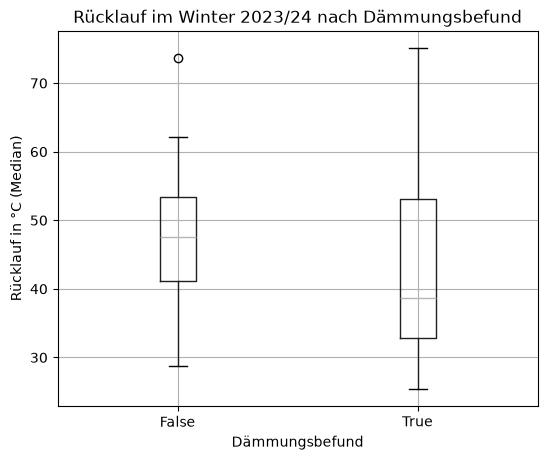

In [11]:
ax = tabelle.boxplot(column="winter_ruecklauf", by="daemmung", figsize=(6, 5))
ax.figure.suptitle("")
ax.set_title("Rücklauf im Winter 2023/24 nach Dämmungsbefund")
ax.set_xlabel("Dämmungsbefund")
ax.set_ylabel("Rücklauf in °C (Median)")


In [12]:
ax.figure.savefig(BILDER / "06_ruecklauf_daemmung.png", bbox_inches="tight")

Die Kästen überlappen sich stark. Mit einer Grenze bei 40 °C findet man 12 der 22 Dämmungsstationen, hat aber auch 7 Fehlalarme bei den 32 ohne Befund.

Dieselben Boxplots für alle Befunde:

In [13]:
einheit = {
    "nachtfluss": "Durchfluss nachts in l/h",
    "winter_ruecklauf": "Rücklauf in °C",
    "winter_spreizung": "Spreizung in K",
    "fluss_pro_kw": "Durchfluss (99 %) in l/h pro kW",
    "ruecklauf_tag": "Rücklauf tagsüber in °C",
    "auslastung": "Leistung (99 %) / Vertrag",
}

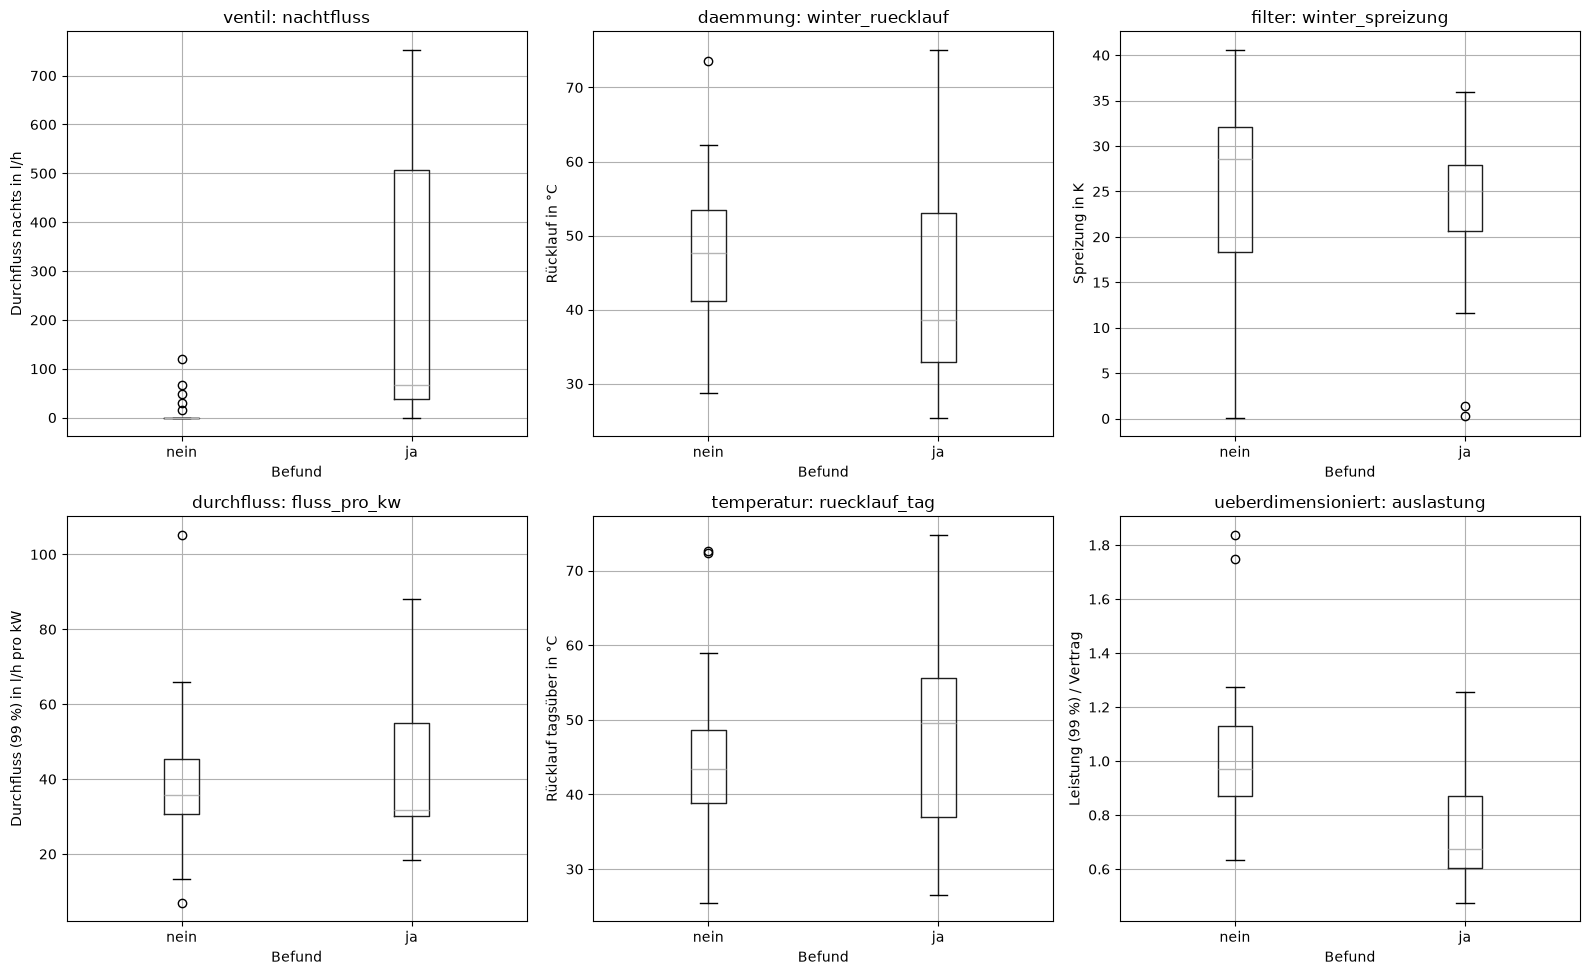

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

for ax, (b, k) in zip(axes.flat, plan.items()):
    tabelle.dropna(subset=[k, b]).boxplot(column=k, by=b, ax=ax)
    ax.set_title(f"{b}: {k}")
    ax.set_xlabel("Befund")
    ax.set_xticklabels(["nein", "ja"])
    ax.set_ylabel(einheit[k])

fig.suptitle("")
fig.tight_layout()

In [15]:
fig.savefig(BILDER / "06_kennzahlen_befunde.png", bbox_inches="tight")

- **Ventil:** Fast alle Stationen ohne Befund haben nachts 0 l/h, die Kästen liegen weit auseinander.
- **Überdimensioniert:** Die Kästen überlappen sich kaum.
- **Dämmung und Temperatur:** Die Mitte ist verschoben, aber die Kästen überlappen sich stark.
- **Filter und Durchfluss:** Die Kästen liegen fast übereinander.

## Schritt 7: Regel, AUC und logistische Regression

Eine Grenze ist immer ein Kompromiss. Die AUC bewertet eine Kennzahl über alle Grenzen: Sie ist die Wahrscheinlichkeit, dass von einem Paar (eine Station mit, eine ohne Befund) die mit Befund den auffälligeren Wert hat. 0,5 ist Raten, 1 ist perfekt.

In [16]:
from sklearn.metrics import roc_auc_score

Dämmung: kälter heißt Befund, deshalb das Minus.

In [17]:
t = tabelle.dropna(subset=["winter_ruecklauf"])
roc_auc_score(t["daemmung"], -t["winter_ruecklauf"])

0.6356534090909091

Ventil: mehr Durchfluss heißt Befund, kein Minus.

In [18]:
t2 = tabelle.dropna(subset=["nachtfluss"])
roc_auc_score(t2["ventil"], t2["nachtfluss"])

0.8777056277056278

Für alle Befunde. Die Richtung kommt aus der Tabelle in Schritt 6: Bei "niedriger" drehen wir mit -1 um. So bedeutet eine AUC über 0,5 immer, dass die Vermutung in die richtige Richtung geht.

In [19]:
richtung = {"ventil": 1, "daemmung": -1, "filter": 1, "durchfluss": 1, "temperatur": 1, "ueberdimensioniert": -1}

for b, k in plan.items():
    tb = tabelle.dropna(subset=[k, b])
    auc = roc_auc_score(tb[b].astype(int), richtung[b] * tb[k])
    print(f"{b:20s} {k:18s} AUC {auc:.2f}   ({int(tb[b].sum())} Fälle von {len(tb)})")

ventil               nachtfluss         AUC 0.88   (11 Fälle von 53)
daemmung             winter_ruecklauf   AUC 0.64   (22 Fälle von 54)
filter               winter_spreizung   AUC 0.36   (25 Fälle von 54)
durchfluss           fluss_pro_kw       AUC 0.50   (19 Fälle von 53)
temperatur           ruecklauf_tag      AUC 0.60   (34 Fälle von 54)
ueberdimensioniert   auslastung         AUC 0.78   (9 Fälle von 35)


- **Ventil 0,88 und Überdimensionierung 0,78:** deutlich besser als Raten.
- **Dämmung 0,64 und Temperatur 0,60:** etwas besser als Raten.
- **Durchfluss 0,50:** Raten.
- **Filter 0,36:** unter 0,5, also eher andersrum als vermutet. Mit Filterbefund ist die Spreizung kleiner. Das drehen wir jetzt aber nicht einfach um, sonst hätten wir die Richtung nach dem Ergebnis gewählt (mehr dazu am Ende von Schritt 8).

### Logistische Regression

Für die schwachen Befunde liegt es nahe, mehrere Kennzahlen zu kombinieren. Das macht eine logistische Regression: Sie lernt für jede Kennzahl ein Gewicht. Vorher ein Test, was passiert, wenn man ein gelerntes Modell auf denselben Stationen prüft, auf denen es gelernt hat. Dafür nehmen wir reine Zufallszahlen:

In [20]:
import numpy as np
from sklearn.linear_model import LogisticRegression

np.random.seed(4)  # damit die Zufallszahlen bei jedem Ausführen gleich sind

In [21]:
zufall = pd.DataFrame(np.random.normal(size=(len(t), 10)))
modell = LogisticRegression()
modell.fit(zufall, t["daemmung"])
roc_auc_score(t["daemmung"], modell.predict_proba(zufall)[:, 1])

0.7528409090909091

Zufallszahlen schaffen auf denselben Stationen eine AUC über 0,7, mehr als der echte Rücklauf. Das Modell hat sich nur gemerkt, welche Station welchen Befund hat (Overfitting). Ehrlich ist nur Leave-one-out: Jede Station wird von einem Modell vorhergesagt, das sie beim Lernen nicht gesehen hat.

In [22]:
from sklearn.model_selection import LeaveOneOut, cross_val_predict

In [23]:
vorhersage = cross_val_predict(LogisticRegression(), zufall, t["daemmung"], cv=LeaveOneOut(), method="predict_proba")[:,1]
roc_auc_score(t["daemmung"], vorhersage)

0.49005681818181823

Mit Leave-one-out ist es nur noch Raten. Jetzt mit echten Kennzahlen, erst mit den beiden aus Phase A:

In [24]:
merkmale= ["nachtfluss", "winter_ruecklauf"]
t= tabelle.dropna(subset=merkmale)

In [25]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

In [26]:
modell = make_pipeline(StandardScaler(), LogisticRegression())
vorhersage = cross_val_predict(modell, t[merkmale], t["daemmung"], cv=LeaveOneOut(), method="predict_proba")[:,1]
roc_auc_score(t["daemmung"], vorhersage)

0.6700879765395894

In [27]:
vorhersage = cross_val_predict(modell, t[merkmale], t["ventil"], cv=LeaveOneOut(), method="predict_proba")[:, 1]
roc_auc_score(t["ventil"], vorhersage)

0.841991341991342

Dämmung 0,67 (allein 0,64), Ventil 0,84 (Nachtdurchfluss allein 0,88). Beim Ventil hilft die zweite Kennzahl nicht. Jetzt für alle Befunde mit allen fünf Kennzahlen, die es für alle Stationen gibt. Die `auslastung` lassen wir weg, weil sie nur 35 Stationen hat:

In [28]:
merkmale_alle = ["nachtfluss", "winter_ruecklauf", "winter_spreizung", "fluss_pro_kw", "ruecklauf_tag"]
t5 = tabelle.dropna(subset=merkmale_alle)
len(t5)

52

In [29]:
for b in ["ventil", "daemmung", "filter", "durchfluss", "temperatur"]:
    vorhersage = cross_val_predict(modell, t5[merkmale_alle], t5[b], cv=LeaveOneOut(), method="predict_proba")[:, 1]
    print(f"{b:12s} logistische Regression, Leave-one-out: AUC {roc_auc_score(t5[b], vorhersage):.2f}")

ventil       logistische Regression, Leave-one-out: AUC 0.78
daemmung     logistische Regression, Leave-one-out: AUC 0.64


filter       logistische Regression, Leave-one-out: AUC 0.55
durchfluss   logistische Regression, Leave-one-out: AUC 0.34


temperatur   logistische Regression, Leave-one-out: AUC 0.35


Mit fünf Kennzahlen wird es nirgends besser als mit der passenden einzelnen Kennzahl: Ventil 0,78 statt 0,88, Dämmung 0,64 statt 0,67 mit zwei Kennzahlen. Bei Filter, Durchfluss und Temperatur findet das Modell nichts. Werte unter 0,5 heißen hier Raten, warum es sogar darunter geht, steht in Schritt 8 beim Zufallstest. Bei rund 50 Stationen und so wenigen Fällen muss das Modell zu viele Gewichte lernen. Die einfache Regel bleibt die Messlatte.

## Schritt 8: Ehrlich prüfen

Bei so wenigen Fällen kann eine AUC viel Zufall enthalten. Mit anderen Stationen käme jedes Mal etwas anderes raus. Wie groß dieser Zufall ist, schätzt der Bootstrap: 1000-mal die Stationen mit Zurücklegen ziehen und jedes Mal die AUC rechnen.

In [30]:
aucs = []
for k in range(1000):
    stichprobe = t.sample(len(t), replace=True)
    aucs.append(roc_auc_score(stichprobe["daemmung"], -stichprobe["winter_ruecklauf"]))

In [31]:
np.percentile(aucs, [2.5, 97.5])

array([0.47347312, 0.81088221])

In [32]:
aucs = []
for k in range(1000):
    stichprobe = t.sample(len(t), replace=True)
    aucs.append(roc_auc_score(stichprobe["ventil"], stichprobe["nachtfluss"]))

In [33]:
np.percentile(aucs, [2.5, 97.5])

array([0.7344898, 0.9888961])

Dämmung ca. 0,47 bis 0,81, die 0,5 liegt drin. Ventil ca. 0,73 bis 0,99, klar besser als Raten. Für alle Befunde mit ihrer Kennzahl und Richtung:

In [34]:
ergebnisse = []
for b, k in plan.items():
    tb = tabelle.dropna(subset=[k, b])
    y = tb[b].astype(int)
    auc = roc_auc_score(y, richtung[b] * tb[k])
    aucs = []
    for i in range(1000):
        s = tb.sample(len(tb), replace=True)
        aucs.append(roc_auc_score(s[b].astype(int), richtung[b] * s[k]))
    ergebnisse.append({"befund": b, "kennzahl": k, "faelle": y.sum(), "stationen": len(tb), "auc": auc,
                       "unten": np.percentile(aucs, 2.5), "oben": np.percentile(aucs, 97.5)})

In [35]:
ergebnisse = pd.DataFrame(ergebnisse)
ergebnisse.round(2)

,befund,kennzahl,faelle,stationen,auc,unten,oben
0,ventil,nachtfluss,11,53,0.88,0.72,0.99
1,daemmung,winter_ruecklauf,22,54,0.64,0.46,0.81
2,filter,winter_spreizung,25,54,0.36,0.22,0.52
3,durchfluss,fluss_pro_kw,19,53,0.50,0.32,0.66
4,temperatur,ruecklauf_tag,34,54,0.60,0.44,0.76
5,ueberdimensioniert,auslastung,9,35,0.78,0.52,0.98


- **Ventil** (0,72 bis 0,99) und **Überdimensionierung** (0,52 bis 0,98): Der Bereich liegt komplett über 0,5.
- **Dämmung** (0,46 bis 0,81) und **Temperatur** (0,44 bis 0,76): Die 0,5 liegt noch drin.
- **Durchfluss** liegt um 0,5, der **Filter** fast komplett darunter.

Bei der Überdimensionierung ist der Bereich sehr breit, weil es nur 9 Fälle gibt.

### Straßen auslassen

Stationen in derselben Straße hängen am selben Strang und wurden meist vom selben Techniker begangen. Wenn die Nachbarin im Training ist, kann ein Modell die Straße wiedererkennen statt den Befund. Deshalb lassen wir ganze Straßen aus:

In [36]:
from sklearn.model_selection import LeaveOneGroupOut

In [37]:
vorhersage = cross_val_predict(modell, t[merkmale], t["daemmung"], cv=LeaveOneGroupOut(), groups=t["strasse_gruppe"], method="predict_proba")[:, 1]
roc_auc_score(t["daemmung"], vorhersage)

0.6612903225806451

Kaum weniger als mit Leave-one-out (0,67). Wenn die AUC stark fallen würde, hätte das Modell von der Straße profitiert. Für alle Befunde mit allen fünf Kennzahlen:

In [38]:
for b in ["ventil", "daemmung", "filter", "durchfluss", "temperatur"]:
    v1 = cross_val_predict(modell, t5[merkmale_alle], t5[b], cv=LeaveOneOut(), method="predict_proba")[:, 1]
    v2 = cross_val_predict(modell, t5[merkmale_alle], t5[b], cv=LeaveOneGroupOut(), groups=t5["strasse_gruppe"], method="predict_proba")[:, 1]
    print(f"{b:12s} Leave-one-out: {roc_auc_score(t5[b], v1):.2f}   Straßen auslassen: {roc_auc_score(t5[b], v2):.2f}")

ventil       Leave-one-out: 0.78   Straßen auslassen: 0.81


daemmung     Leave-one-out: 0.64   Straßen auslassen: 0.65


filter       Leave-one-out: 0.55   Straßen auslassen: 0.55


durchfluss   Leave-one-out: 0.34   Straßen auslassen: 0.26


temperatur   Leave-one-out: 0.35   Straßen auslassen: 0.41


Beim Ventil und bei der Dämmung ändert sich fast nichts, die Straße spielt dort kaum eine Rolle. Bei Filter, Durchfluss und Temperatur findet das Modell sowieso nichts, da schwanken die Werte nur.

### Zufallstest

Labels durchmischen, sodass kein Befund mehr zu seiner Station passt, und schauen, was der Zufall schafft. Erst für die logistische Regression bei der Dämmung (wie oft schafft der Zufall die 0,67?):

In [39]:
zufalls_aucs = []
for k in range(200):
    gemischt = t["daemmung"].sample(frac=1).values
    v = cross_val_predict(modell, t[merkmale], gemischt, cv=LeaveOneOut(), method="predict_proba")[:, 1]
    zufalls_aucs.append(roc_auc_score(gemischt, v))

In [40]:
(np.array(zufalls_aucs) >= 0.67).mean()

np.float64(0.005)

Nur in 1 von 200 Durchläufen. Bei Leave-one-out liegt der Zufall im Mittel sogar unter 0,5:

In [41]:
np.median(zufalls_aucs)

np.float64(0.34824046920821117)

Das ist eine Eigenheit von Leave-one-out bei wenigen Fällen. Deshalb vergleicht man mit gemischten Labels und nicht einfach mit 0,5. Das erklärt auch die Werte unter 0,5 bei der logistischen Regression in Schritt 7.

Für die einfachen Regeln aus Schritt 6 geht der Zufallstest schneller, weil nichts gelernt wird. Wie oft kommt der Zufall mindestens auf die echte AUC?

In [42]:
zufall_anteil = []
for b, k in plan.items():
    tb = tabelle.dropna(subset=[k, b])
    echt = roc_auc_score(tb[b].astype(int), richtung[b] * tb[k])
    zufalls = []
    for i in range(1000):
        gemischt = tb[b].astype(int).sample(frac=1).values
        zufalls.append(roc_auc_score(gemischt, richtung[b] * tb[k]))
    zufall_anteil.append((np.array(zufalls) >= echt).mean())

ergebnisse["zufall_anteil"] = zufall_anteil
ergebnisse.round(3)

,befund,kennzahl,faelle,stationen,auc,unten,oben,zufall_anteil
0,ventil,nachtfluss,11,53,0.878,0.722,0.988,0.000
1,daemmung,winter_ruecklauf,22,54,0.636,0.461,0.814,0.047
2,filter,winter_spreizung,25,54,0.356,0.220,0.522,0.968
3,durchfluss,fluss_pro_kw,19,53,0.495,0.322,0.662,0.504
4,temperatur,ruecklauf_tag,34,54,0.600,0.441,0.763,0.125
5,ueberdimensioniert,auslastung,9,35,0.778,0.515,0.976,0.008


`zufall_anteil` ist der Anteil der 1000 Durchläufe, in denen der Zufall mindestens so gut war wie die echte Kennzahl:

- **Ventil** 0,000 und **Überdimensionierung** 0,008: Der Zufall schafft das praktisch nie.
- **Dämmung** 0,047: in knapp 5 % der Durchläufe. Ein Signal, aber knapp.
- **Temperatur** 0,125: In jedem achten Durchlauf ist der Zufall genauso gut. Das reicht nicht.
- **Durchfluss** 0,504 und **Filter** 0,968: kein Signal in die vermutete Richtung.

### Auswahl

Hätten wir für jeden Befund zehn Kennzahlen ausprobiert und dann die beste genommen, wäre deren AUC wieder zu gut, weil die Auswahl die Antworten schon kennt. Deshalb stehen die Kennzahlen und ihre Richtung oben in Schritt 6, bevor gerechnet wurde. Wenn eine Vermutung nicht stimmt, wie beim Filter, wird sie nicht nachträglich umgedreht. Will man doch auswählen, muss die Auswahl in jedem Durchlauf nur auf den Trainingsstationen passieren (verschachtelte Kreuzvalidierung).

## Ergebnis Phase B

| Befund | Fälle | Kennzahl | AUC | 95-%-Bereich | Zufall mind. so gut | erkennbar? |
|---|---|---|---|---|---|---|
| Ventil | 11 | nachtfluss | 0,88 | 0,72 bis 0,99 | 0 % | ja |
| Überdimensioniert | 9 (von 35) | auslastung | 0,78 | 0,52 bis 0,98 | 0,8 % | ja, aber wenige Fälle |
| Dämmung | 22 | winter_ruecklauf | 0,64 | 0,46 bis 0,81 | 4,7 % | schwach |
| Temperatur | 34 | ruecklauf_tag | 0,60 | 0,44 bis 0,76 | 12,5 % | nein, höchstens eine Andeutung |
| Durchfluss | 19 | fluss_pro_kw | 0,50 | 0,32 bis 0,66 | 50 % | nein |
| Filter | 25 | winter_spreizung | 0,36 | 0,22 bis 0,52 | 97 % | nein, Vermutung falsch |

Mit einfachen Kennzahlen sind das Ventil und die Überdimensionierung gut erkennbar, die Dämmung schwach. Filter, Durchfluss und Temperatur nicht. Das passt zu Phase A: Bei Dämmung, Filter und Temperatur hat sich an den Beispielstationen durch die Begehung kaum etwas geändert. Außerdem wurden diese Maßnahmen bei sehr vielen Stationen gemacht (Temperatur bei 36 von 56), das ist eher Wartung als ein Fehler.

Die logistische Regression war nirgends besser als die passende einzelne Kennzahl. Das ist die Messlatte für das LSTM ab Phase C.